# 03: Dense baseline (condition B) and the coverage ceiling

Condition B embeds every question and every paper with the frozen **Qwen3-Embedding-4B** (a bi-encoder: question and paper are encoded separately into vectors), ranks all candidate papers by inner product with FAISS, and keeps the top 100. Those 100 papers are the **shortlist** that conditions C, D and E rescore.

Two questions for this notebook:
1. **Reproduction gate.** Is our core Recall@20 within 0.03 of the published 0.39 (ScholarCatalyst, arXiv:2610.02202, Table 3, checked against the paper's HTML on Nov 23)?
2. **Coverage ceiling.** A reranker only reorders the shortlist, so for every question
$$\text{Recall@20}_{\text{final}} \le \text{Recall@100}_{B}.$$
How much of the credited set does B's top 100 actually hold?

Inputs: `results/shortlist_B.parquet` and `results/metrics_B.csv` (written by `scripts/encode_corpus.py --config configs/B.yaml` on one A40, Nov 21), `results/metrics_B06.csv` and `results/shortlist_B06.parquet` (same settings with the frozen Qwen3-Embedding-0.6B, the RQ3 control), and `results/run_A.parquet` (BM25, condition A).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from insight import data, metrics, diagnose
pd.set_option("display.precision", 4)
R = data.ROOT / "results"
ds = data.load()
table = ds.table
runs = {"A": pd.read_parquet(R / "run_A.parquet"),
        "B": pd.read_parquet(R / "shortlist_B.parquet"),
        "B06": pd.read_parquet(R / "shortlist_B06.parquet")}
for name, run in runs.items():
    n = run.groupby("query_id").size()
    print(f"{name}: {len(run)} rows, {run.query_id.nunique()} questions, {n.min()} to {n.max()} papers per question")

A: 89400 rows, 894 questions, 100 to 100 papers per question
B: 89400 rows, 894 questions, 100 to 100 papers per question
B06: 89400 rows, 894 questions, 100 to 100 papers per question


## Sanity checks on the shortlist

Before trusting the committed metrics: (1) recomputing them from the shortlist with `insight.metrics` must give the committed per-question file exactly; (2) ranks must be 1 to 100 in descending score order; (3) no shortlisted paper may break the date filter (`configs/data.yaml`: unlabeled papers published after the question's source paper are not allowed).

In [2]:
ranked = {q: g.sort_values("rank").doc_id.tolist() for q, g in runs["B"].groupby("query_id")}
recomputed = metrics.evaluate(ranked, table.positives.to_dict())
committed = pd.read_csv(R / "metrics_B.csv", index_col="query_id")
cols = ["recall@5", "recall@20", "recall@100", "ndcg@20", "mrr"]
diff = (recomputed.loc[committed.index, cols] - committed[cols]).abs().to_numpy().max()
print("max |recomputed - committed| over 894 questions:", diff)

ok_rank = runs["B"].groupby("query_id").apply(lambda g: (g.sort_values("rank").score.diff().dropna() <= 0).all() and sorted(g["rank"]) == list(range(1, 101)))
print("questions with ranks 1..100 in descending score order:", int(ok_rank.sum()), "of", len(ok_rank))

pos_of = {d: i for i, d in enumerate(ds.corpus.id)}
mask = data.mask_fn(ds.corpus, table, data.DataConfig.from_yaml(data.ROOT / "configs" / "data.yaml"))
violations = sum((~mask(q)[[pos_of[d] for d in g.doc_id]]).sum() for q, g in runs["B"].groupby("query_id"))
print("shortlisted papers that the date filter forbids:", int(violations))

max |recomputed - committed| over 894 questions: 0.0


questions with ranks 1..100 in descending score order: 894 of 894


shortlisted papers that the date filter forbids: 0


## Reproduction gate: our numbers vs the paper

Paper values are Table 3, row Qwen3-Emb-4B. Metrics: **Recall@K** is (credited papers in the top $K$) / (all credited papers), averaged over questions; **nDCG@20** also rewards putting credited papers higher (a hit at rank $r$ counts $1/\log_2(r+1)$, normalized by the best possible order); **MRR** is the average of $1/\text{rank}$ of the first credited paper (not reported by the paper).

In [3]:
paper = pd.DataFrame({"core": {"ndcg@20": 0.25, "recall@5": 0.18, "recall@20": 0.39, "recall@100": 0.59},
                      "subfield": {"ndcg@20": 0.35, "recall@5": 0.21, "recall@20": 0.44, "recall@100": 0.69}}).T
ours = committed.groupby("kind")[paper.columns].mean()
pd.concat({"ours": ours, "paper": paper, "diff": ours - paper}, axis=1)

ours                                 paper                     \
         ndcg@20 recall@5 recall@20 recall@100 ndcg@20 recall@5 recall@20   
core      0.2539   0.1846    0.3785     0.5971    0.25     0.18      0.39   
subfield  0.3663   0.2233    0.4489     0.6967    0.35     0.21      0.44   

                       diff                                
         recall@100 ndcg@20 recall@5 recall@20 recall@100  
core           0.59  0.0039   0.0046   -0.0115     0.0071  
subfield       0.69  0.0163   0.0133    0.0089     0.0067

In [4]:
for kind in ["core", "subfield"]:
    gap = ours.loc[kind, "recall@20"] - paper.loc[kind, "recall@20"]
    print(f"{kind}: Recall@20 {ours.loc[kind, 'recall@20']:.4f}, gap {gap:+.4f}, |gap| <= 0.03: {'PASS' if abs(gap) <= 0.03 else 'FAIL'}")

core: Recall@20 0.3785, gap -0.0115, |gap| <= 0.03: PASS
subfield: Recall@20 0.4489, gap +0.0089, |gap| <= 0.03: PASS


The paper reports two decimals, so a difference under 0.005 is within its rounding.

## A, B and the frozen 0.6B side by side

In [5]:
per_q = {"A": pd.read_csv(R / "metrics_A.csv", index_col="query_id"),
         "B": committed,
         "B06": pd.read_csv(R / "metrics_B06.csv", index_col="query_id")}
side = pd.concat({k: v.groupby("kind")[cols].mean() for k, v in per_q.items()})
side

recall@5  recall@20  recall@100  ndcg@20     mrr
    kind                                                      
A   core        0.1225     0.2406      0.4171   0.1644  0.2349
    subfield    0.1270     0.2853      0.4876   0.2275  0.3536
B   core        0.1846     0.3785      0.5971   0.2539  0.3162
    subfield    0.2233     0.4489      0.6967   0.3663  0.4965
B06 core        0.1887     0.3270      0.5288   0.2345  0.3180
    subfield    0.1733     0.3667      0.5971   0.2957  0.4226

## The coverage ceiling

Recall@100 is a mean over questions; it hides how uneven coverage is. Below, per question: the share of questions whose top 100 holds **all** of their credited papers, **none** of them, and the share of credited (question, paper) **pairs** outside the top 100 (pairs, not a per-question mean, so a question with 10 credited papers weighs more).

In [6]:
def coverage(per_question, run):
    pairs = diagnose.credited_ranks(run, table)
    out = {}
    for kind, g in per_question.groupby("kind"):
        r100 = g["recall@100"]
        p = pairs[pairs.kind == kind]
        out[kind] = {"questions": len(g), "mean Recall@100": r100.mean(),
                     "share with all credited in top 100": (r100 == 1).mean(),
                     "share with none in top 100": (r100 == 0).mean(),
                     "credited pairs": len(p),
                     "share of pairs beyond 100": p["rank"].isna().mean()}
    return pd.DataFrame(out).T
cov = pd.concat({k: coverage(per_q[k], runs[k]) for k in ["A", "B", "B06"]})
cov

questions  mean Recall@100  share with all credited in top 100  \
A   core          207.0           0.4171                              0.1449   
    subfield      687.0           0.4876                              0.1339   
B   core          207.0           0.5971                              0.2995   
    subfield      687.0           0.6967                              0.3217   
B06 core          207.0           0.5288                              0.2271   
    subfield      687.0           0.5971                              0.2111   

              share with none in top 100  credited pairs  \
A   core                          0.2705           661.0   
    subfield                      0.1441          4184.0   
B   core                          0.1449           661.0   
    subfield                      0.0670          4184.0   
B06 core                          0.1836           661.0   
    subfield                      0.1048          4184.0   

              share of pairs beyond 100  
A   core                         0.6036  
    subfield                     0.5153  
B   core                         0.4160  
    subfield                     0.2820  
B06 core                         0.4962  
    subfield                     0.3908

## How recall grows with depth

Recall@$K$ for every $K$ from 1 to 100, for each retriever, so we can read off how deep the shortlist would have to be for a given coverage, and how much room a reranker has between rank 20 and rank 100.

A                B              B06         
kind    core subfield    core subfield    core subfield
1     0.0443   0.0442  0.0699   0.0691  0.0747   0.0563
5     0.1225   0.1270  0.1846   0.2233  0.1887   0.1733
10    0.1825   0.1996  0.2849   0.3256  0.2433   0.2539
20    0.2406   0.2853  0.3785   0.4489  0.3270   0.3667
50    0.3205   0.4014  0.5043   0.6021  0.4184   0.4961
100   0.4171   0.4876  0.5971   0.6967  0.5288   0.5971

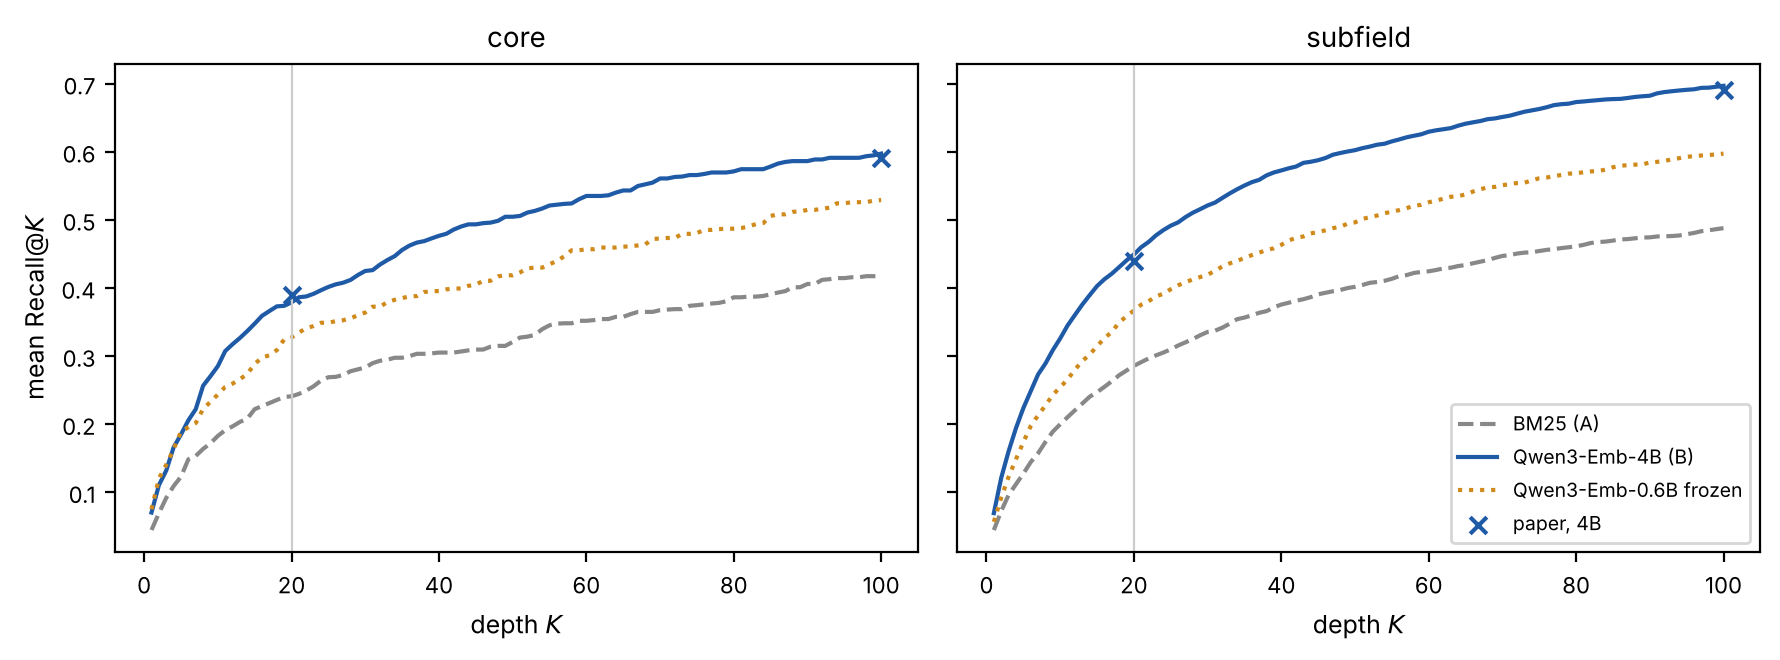

In [7]:
def recall_curve(run, ks=range(1, 101)):
    pairs = diagnose.credited_ranks(run, table)
    n_pos = pairs.groupby("query_id").size()
    out = {}
    for k in ks:
        hit = pairs.assign(h=pairs["rank"] <= k).groupby("query_id").h.sum()
        out[k] = (hit / n_pos)
    curve = pd.DataFrame(out)
    return curve.groupby(table.kind.loc[curve.index]).mean().T

curves = {k: recall_curve(runs[k]) for k in runs}
# the curve must agree with the per-question metric files at K = 20 and 100
for k in runs:
    for K in (20, 100):
        assert np.allclose(curves[k].loc[K], per_q[k].groupby("kind")[f"recall@{K}"].mean().loc[curves[k].columns])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
styles = {"A": ("BM25 (A)", "#888888", "--"), "B": ("Qwen3-Emb-4B (B)", "#1f5aa6", "-"), "B06": ("Qwen3-Emb-0.6B frozen", "#d08a1c", ":")}
for ax, kind in zip(axes, ["core", "subfield"]):
    for k, (lab, col, ls) in styles.items():
        ax.plot(curves[k].index, curves[k][kind], color=col, ls=ls, label=lab)
    ax.scatter([20, 100], paper.loc[kind, ["recall@20", "recall@100"]], color="#1f5aa6", marker="x", zorder=3, label="paper, 4B")
    ax.axvline(20, color="#cccccc", lw=0.8); ax.set_title(kind, fontsize=10); ax.set_xlabel("depth $K$", fontsize=9)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("mean Recall@$K$", fontsize=9); axes[1].legend(fontsize=7, loc="lower right")
fig.tight_layout()
(R / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(R / "figures" / "recall_by_depth_ABB06.png", dpi=150, bbox_inches="tight")
pd.concat({k: c.loc[[1, 5, 10, 20, 50, 100]] for k, c in curves.items()}, axis=1)

<small>Figure: mean Recall@$K$ (y) against shortlist depth $K$ (x), left core questions (207), right subfield questions (687). Grey dashed: BM25 (condition A); solid blue: frozen Qwen3-Embedding-4B (condition B); orange dotted: frozen Qwen3-Embedding-0.6B (RQ3 control); blue crosses: the paper's Recall@20 and Recall@100 for the 4B model; vertical line: $K = 20$, the cutoff the reranker is judged at. Saved as `results/figures/recall_by_depth_ABB06.png`.</small>

## Do BM25 and the embedder find the same credited papers?

If BM25 reaches credited papers that B misses, a hybrid first stage could widen coverage without training. Counted over credited (question, paper) pairs: in B's top 100 only, in A's only, in both, in neither.

In [8]:
def in_top(run, k=100):
    return set(zip(run.query_id[run["rank"] <= k], run.doc_id[run["rank"] <= k]))
pairs = diagnose.credited_ranks(runs["B"], table)[["query_id", "kind", "doc_id"]]
topA, topB = in_top(runs["A"]), in_top(runs["B"])
key = list(zip(pairs.query_id, pairs.doc_id))
pairs["A"] = [k in topA for k in key]; pairs["B"] = [k in topB for k in key]
pairs["found_in"] = np.select([pairs.A & pairs.B, pairs.B, pairs.A], ["both", "B only", "A only"], "neither")
overlap = pd.crosstab(pairs.kind, pairs.found_in, normalize="index")[["both", "B only", "A only", "neither"]]
overlap["either (union)"] = 1 - overlap["neither"]
overlap

found_in,both,B only,A only,neither,either (union)
kind,,,,,
core,0.3525,0.2315,0.0439,0.3722,0.6278
subfield,0.4175,0.3004,0.0672,0.2149,0.7851


The union is a share of pairs and an upper bound on what merging the two top-100 lists could reach; a merged list would hold up to 200 papers, so it is not a like-for-like Recall@100.

## Where B's misses sit (rank bins)

The RQ1 view in its simplest form: for every credited pair, B's rank bin. Rank 1 to 20 is found; 21 to 100 is on the shortlist but too low (a reranker can fix it, RQ2); beyond 100 never reaches the shortlist (only better retrieval can fix it, RQ3). The full breakdown by field and type is notebook 04 and 05.

In [9]:
rb = diagnose.credited_ranks(runs["B"], table)
rb["bin"] = diagnose.rank_bin(rb["rank"])
bins = pd.crosstab(rb.kind, rb.bin, normalize="index")
bins["n pairs"] = rb.groupby("kind").size()
bins

bin,1 to 20,21 to 100,beyond 100,n pairs
kind,,,,
core,0.3631,0.2209,0.416,661
subfield,0.4500,0.2679,0.282,4184


## Summary

All numbers are outputs of the cells above.

- **Checks.** Recomputing the metrics from the committed shortlist reproduces `results/metrics_B.csv` exactly (max difference 0.0); all 894 questions have ranks 1 to 100 in score order; no shortlisted paper breaks the date filter.
- **Gate passes for B.** Core Recall@20 0.3785 vs the paper's 0.39 (gap $-0.0115$), subfield 0.4489 vs 0.44 ($+0.0089$). Every other Table 3 metric is within 0.017 (largest: subfield nDCG@20 0.3663 vs 0.35). Both A and B now pass, so training results can be read against a reproduced baseline.
- **Coverage ceiling.** B's mean Recall@100 is 0.5971 (core) and 0.6967 (subfield), paper 0.59 and 0.69. So no reranker over this shortlist can exceed core Recall@20 0.5971. Coverage is uneven: 29.9% of core questions have all their credited papers in the top 100, and 14.5% have none.
- **Where B's credited pairs sit.** Core: 36.3% at ranks 1 to 20, 22.1% at 21 to 100, 41.6% beyond 100. Subfield: 45.0%, 26.8%, 28.2%. For core questions the beyond-100 share (only retrieval can fix it) is larger than the 21-to-100 share (a reranker can fix it).
- **Depth.** Going from $K = 20$ to $K = 100$ raises B's core recall from 0.3785 to 0.5971; at $K = 50$ it is 0.5043.
- **BM25 and B are partly complementary.** 4.4% (core) and 6.7% (subfield) of credited pairs are in A's top 100 but not B's; the union of the two top-100 lists holds 62.8% and 78.5% of credited pairs, vs 58.4% and 71.8% for B alone. This is an upper bound for a merged list of up to 200 papers, not a Recall@100.
- **Frozen 0.6B (RQ3 start).** Core Recall@100 0.5288 and subfield 0.5971, below B's 0.5971 and 0.6967. Fine-tuning the 0.6B must gain about 0.07 (core) and 0.10 (subfield) Recall@100 just to match the frozen 4B shortlist. Its core Recall@5 (0.1887) and MRR (0.3180) are slightly above B's (0.1846, 0.3162); on core questions the 0.6B is slightly ahead at depths 1, 2, 3 and 5 (by at most 0.0098, checked over all depths 1 to 100 when this notebook was written) and the 4B at every other depth; on subfield questions the 4B is ahead at every depth.